## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
# Настройка стиля для графиков
sns.set_theme(style='whitegrid', palette='husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14

## Data

In [3]:
TRAIN_PATH = Path("../data/processed/train.csv")

In [4]:
df = pd.read_csv(TRAIN_PATH)

#### Обзор данных:

In [5]:
print(f'Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов')
print(f'Первые 5 строк:')
display(df.head())

Размер датасета: 12000 строк, 14 столбцов
Первые 5 строк:


,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,12140,15809872.0,Nwabugwu,710.0,France,Female,36.0,7.0,0.00,1.0,1.0,1.0,62367.35,0.0
1,6188,15602405.0,Bellucci,582.0,France,Male,37.0,4.0,0.00,1.0,1.0,0.0,127939.18,0.0
2,6956,15615177.0,Chizuoke,731.0,France,Male,41.0,4.0,0.00,1.0,1.0,1.0,86410.29,0.0
3,9246,15607986.0,Onyekachi,587.0,Germany,Male,54.0,0.0,76319.64,1.0,1.0,0.0,129870.93,1.0
4,8176,15690540.0,Ukaegbunam,567.0,Germany,Male,34.0,1.0,143500.82,2.0,0.0,1.0,110472.12,0.0


In [6]:
df.dtypes

id                   int64
CustomerId         float64
Surname                str
CreditScore        float64
Geography              str
Gender                 str
Age                float64
Tenure             float64
Balance            float64
NumOfProducts      float64
HasCrCard          float64
IsActiveMember     float64
EstimatedSalary    float64
Exited             float64
dtype: object

In [7]:
print(f'Базовая статистика:')
df.describe()

Базовая статистика:


,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,12000.000000,1.200000e+04,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,12000.00000,12000.000000,12000.000000,12000.000000
mean,7504.399833,1.569133e+07,657.877250,37.887750,5.037833,42346.632242,1.584500,0.77925,0.495167,117780.913799,0.201167
std,4330.116659,1.472178e+05,72.885352,8.159046,2.801617,59503.059376,0.527146,0.41477,0.499997,45846.375705,0.400889
min,1.000000,1.574723e+06,437.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.570000,0.000000
25%,3769.750000,1.563602e+07,600.000000,32.000000,3.000000,0.000000,1.000000,1.00000,0.000000,83090.350000,0.000000
50%,7506.000000,1.568995e+07,659.000000,37.000000,5.000000,0.000000,2.000000,1.00000,0.000000,123475.880000,0.000000
75%,11261.250000,1.575760e+07,708.000000,42.000000,7.000000,108895.930000,2.000000,1.00000,1.000000,157097.090000,0.000000
max,14997.000000,1.581567e+07,850.000000,72.000000,20.000000,187911.550000,4.000000,1.00000,1.000000,199953.330000,1.000000


In [8]:
print(f'Информация о пропусках:')
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Пропуски': missing, 'Процент': missing_percent})
missing_df = missing_df[missing_df['Пропуски'] > 0].sort_values('Процент', ascending=False)
print(missing_df if not missing_df.empty else 'Пропусков нет!')

Информация о пропусках:
Пропусков нет!


#### Анализ целевой переменной (Exited)

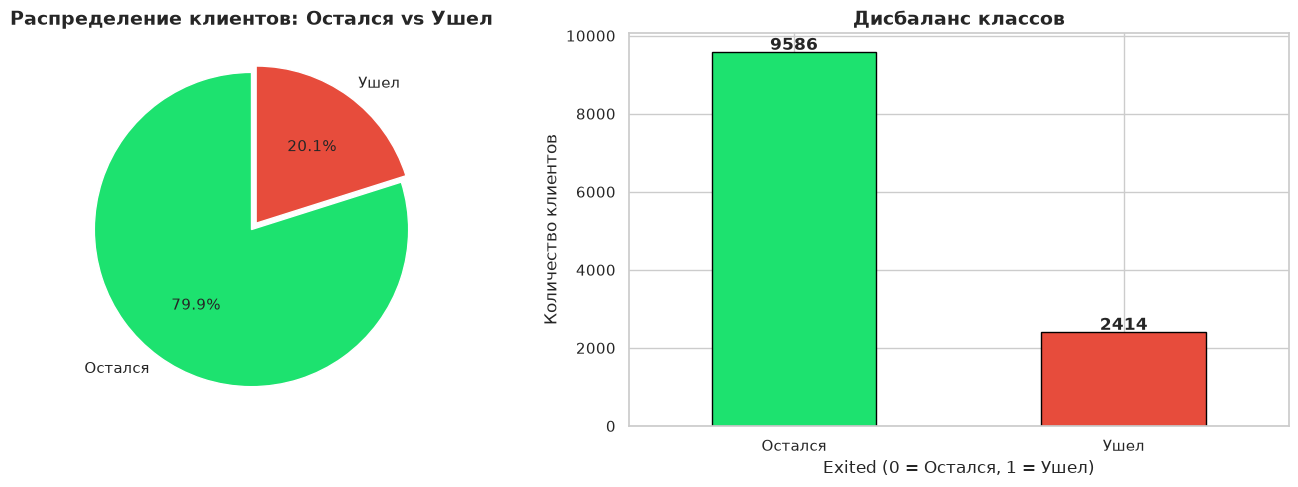

Общая доля оттока: 20.12%
Соотношение классов: 9586:2414 ≈ 4.0:1


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Количество клиентов по классам:
exited_counts = df['Exited'].value_counts()
axes[0].pie(exited_counts, labels=['Остался', 'Ушел'], autopct='%1.1f%%', 
            colors=["#1de26f", '#e74c3c'], startangle=90, explode=(0, 0.05))
axes[0].set_title('Распределение клиентов: Остался vs Ушел', fontsize=14, fontweight='bold')

# Столбчатая диаграмма:
exited_counts.plot(kind='bar', ax=axes[1], color=['#1de26f', '#e74c3c'], edgecolor='black')
axes[1].set_xlabel('Exited (0 = Остался, 1 = Ушел)', fontsize=12)
axes[1].set_ylabel('Количество клиентов', fontsize=12)
axes[1].set_title('Дисбаланс классов', fontsize=14, fontweight='bold')
axes[1].set_xticklabels(['Остался', 'Ушел'], rotation=0)

for i, v in enumerate(exited_counts):
    axes[1].text(i, v + 50, str(v), ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

churn_rate = df['Exited'].mean()
print(f'Общая доля оттока: {churn_rate:.2%}')
print(f'Соотношение классов: {exited_counts[0]}:{exited_counts[1]} ≈ {exited_counts[0]/exited_counts[1]:.1f}:1')


#### Униварный анализ категориальных признаков

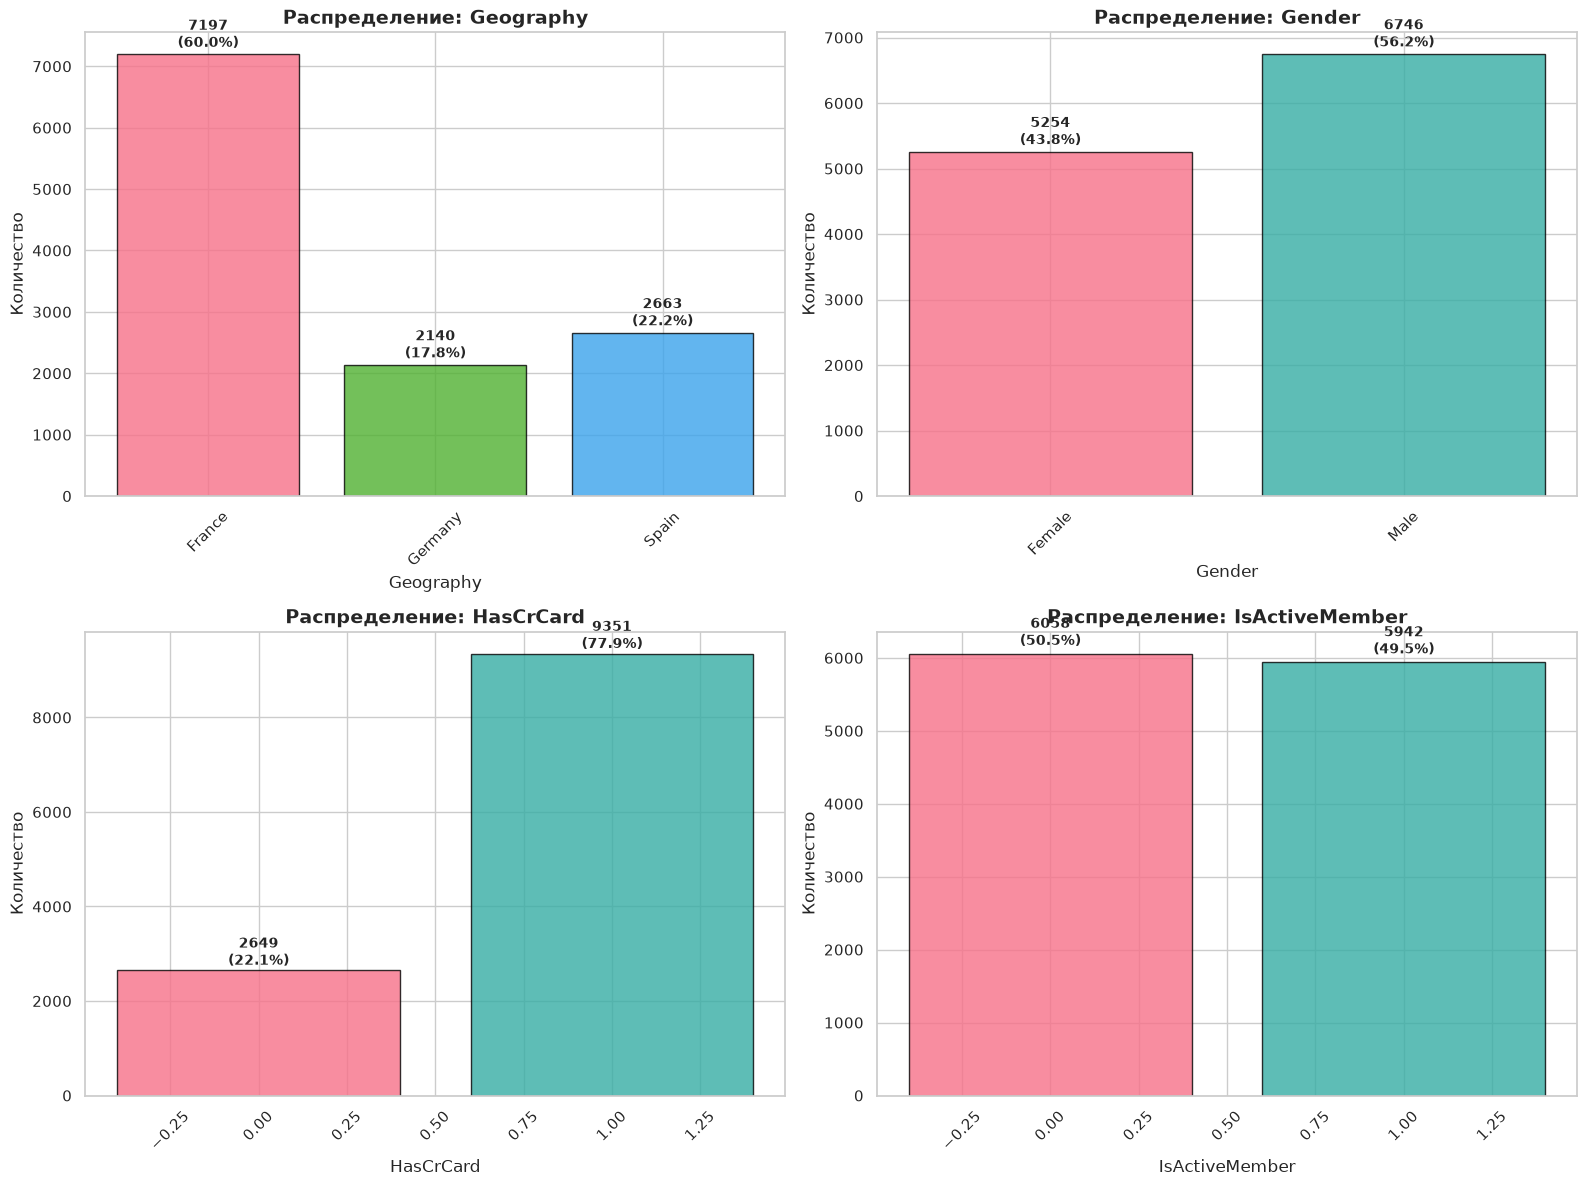

In [10]:
categorical_cols = ['Geography', 'Gender', 'HasCrCard', 'IsActiveMember']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(categorical_cols):
    if idx < len(axes):
        value_counts = df[col].value_counts().sort_index()
        axes[idx].bar(value_counts.index, value_counts.values, 
                     color=sns.color_palette('husl', len(value_counts)),
                     edgecolor='black', alpha=0.8)
        axes[idx].set_title(f'Распределение: {col}', fontsize=14, fontweight='bold')
        axes[idx].set_xlabel(col, fontsize=12)
        axes[idx].set_ylabel('Количество', fontsize=12)
        
        # Добавляем проценты
        total = value_counts.sum()        
        for i, v in enumerate(value_counts.values):
            percent = (v / total) * 100
            axes[idx].text(i, v + (total * 0.01), f'{v}\n({percent:.1f}%)', 
                          ha='center', fontweight='bold', fontsize=10)
        
        plt.setp(axes[idx].xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()


#### Биварный анализ: категориальные признаки vs целевая переменная (Exited)

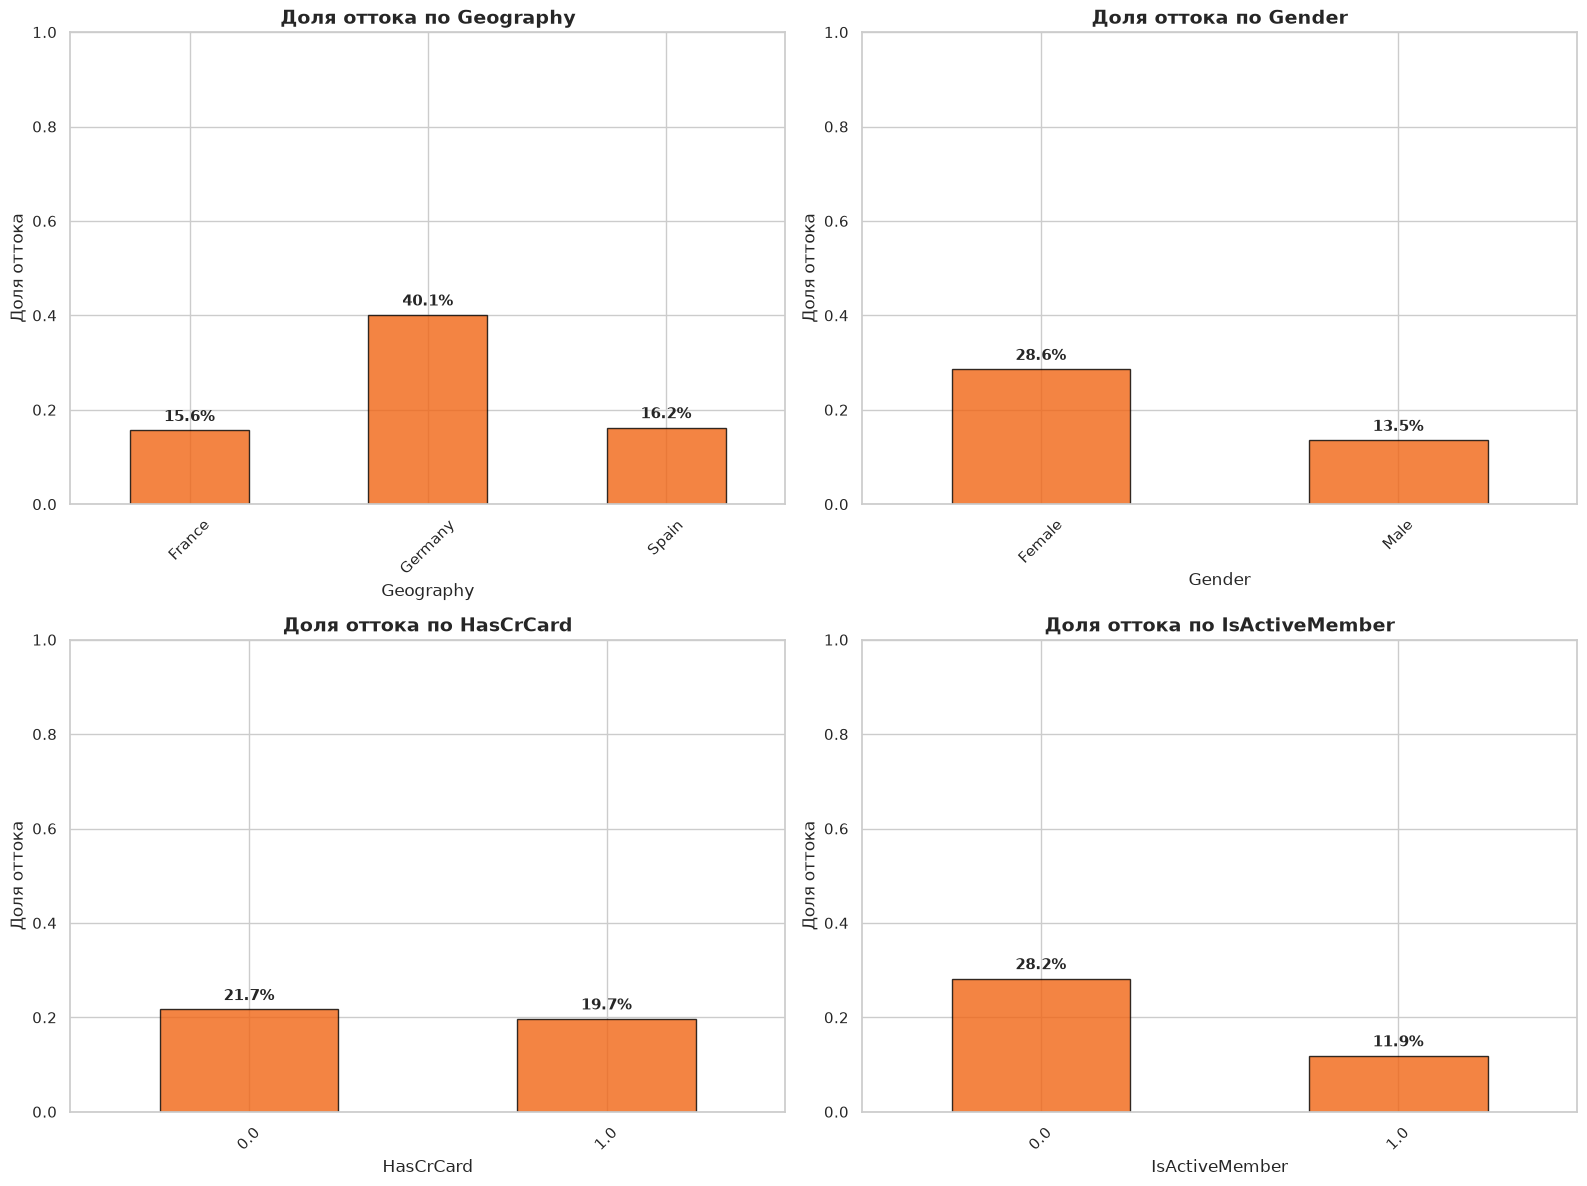

Детальная таблица оттока по категориям:
---------------------------------------------

Geography:
           Всего    Ушло Доля оттока
Geography                           
France      7197  1124.0       15.6%
Germany     2140   858.0       40.1%
Spain       2663   432.0       16.2%

Gender:
        Всего    Ушло Доля оттока
Gender                           
Female   5254  1501.0       28.6%
Male     6746   913.0       13.5%

HasCrCard:
           Всего    Ушло Доля оттока
HasCrCard                           
0.0         2649   574.0       21.7%
1.0         9351  1840.0       19.7%

IsActiveMember:
                Всего    Ушло Доля оттока
IsActiveMember                           
0.0              6058  1709.0       28.2%
1.0              5942   705.0       11.9%


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(categorical_cols):
    if idx < len(axes):
        churn_by_category = df.groupby([col, 'Exited']).size().unstack(fill_value=0)
        churn_rate_by_category = churn_by_category.div(churn_by_category.sum(axis=1), axis=0)
        
        # График оттока по категориям
        churn_rate_by_category[1].plot(kind='bar', ax=axes[idx], 
                                       color="#f16514", edgecolor='black', alpha=0.8)
        axes[idx].set_title(f'Доля оттока по {col}', fontsize=14, fontweight='bold')
        axes[idx].set_xlabel(col, fontsize=12)
        axes[idx].set_ylabel('Доля оттока', fontsize=12)
        axes[idx].set_ylim(0, 1)
        
        # Добавляем значения
        for i, v in enumerate(churn_rate_by_category[1]):
            axes[idx].text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold', fontsize=11)
        
        plt.setp(axes[idx].xaxis.get_majorticklabels(), rotation=45)

plt.tight_layout()
plt.show()

# Таблица с детальным анализом
print('Детальная таблица оттока по категориям:')
print('-' * 45)
for col in categorical_cols:
    print(f'\n{col}:')
    churn_table = df.groupby(col)['Exited'].agg(['count', 'sum', 'mean']).round(3)
    churn_table.columns = ['Всего', 'Ушло', 'Доля оттока']
    churn_table['Доля оттока'] = churn_table['Доля оттока'].apply(lambda x: f'{x:.1%}')
    print(churn_table)


#### Униварный анализ численных признаков

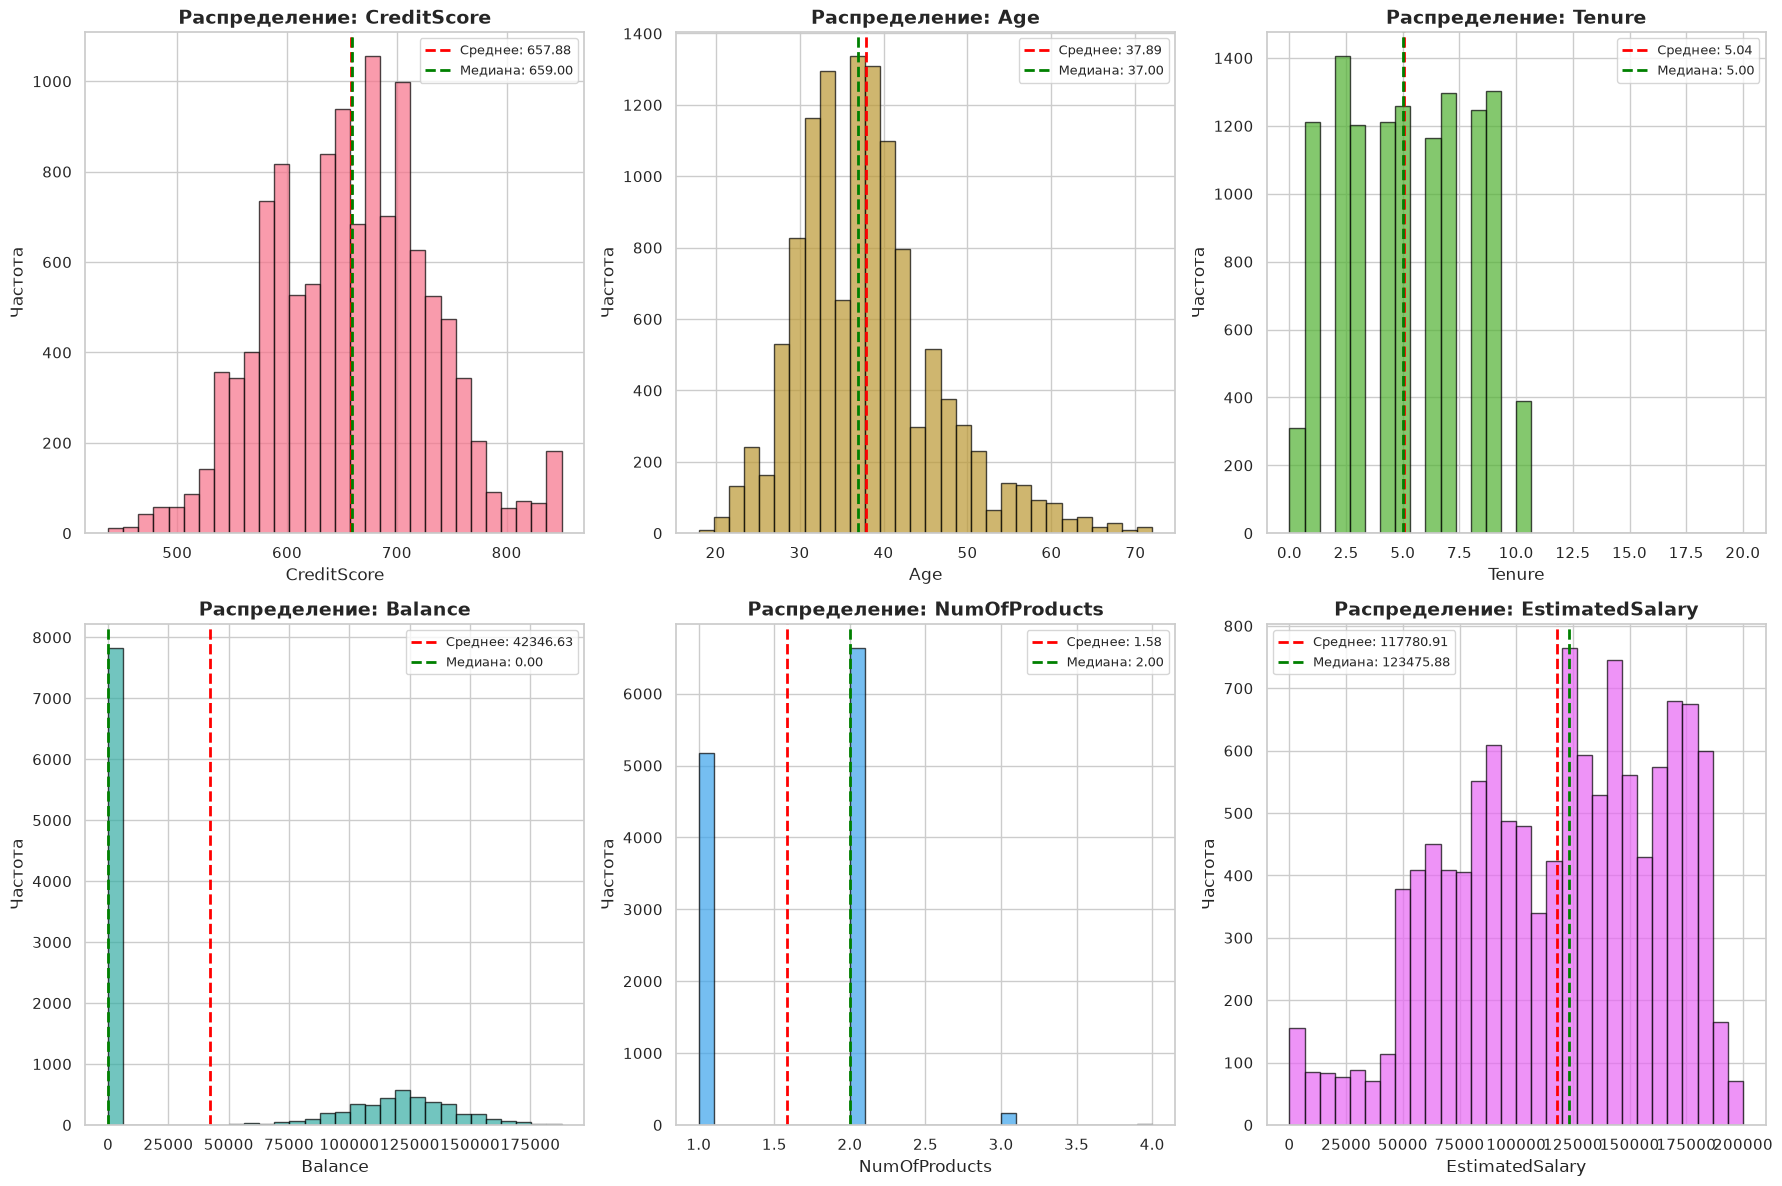

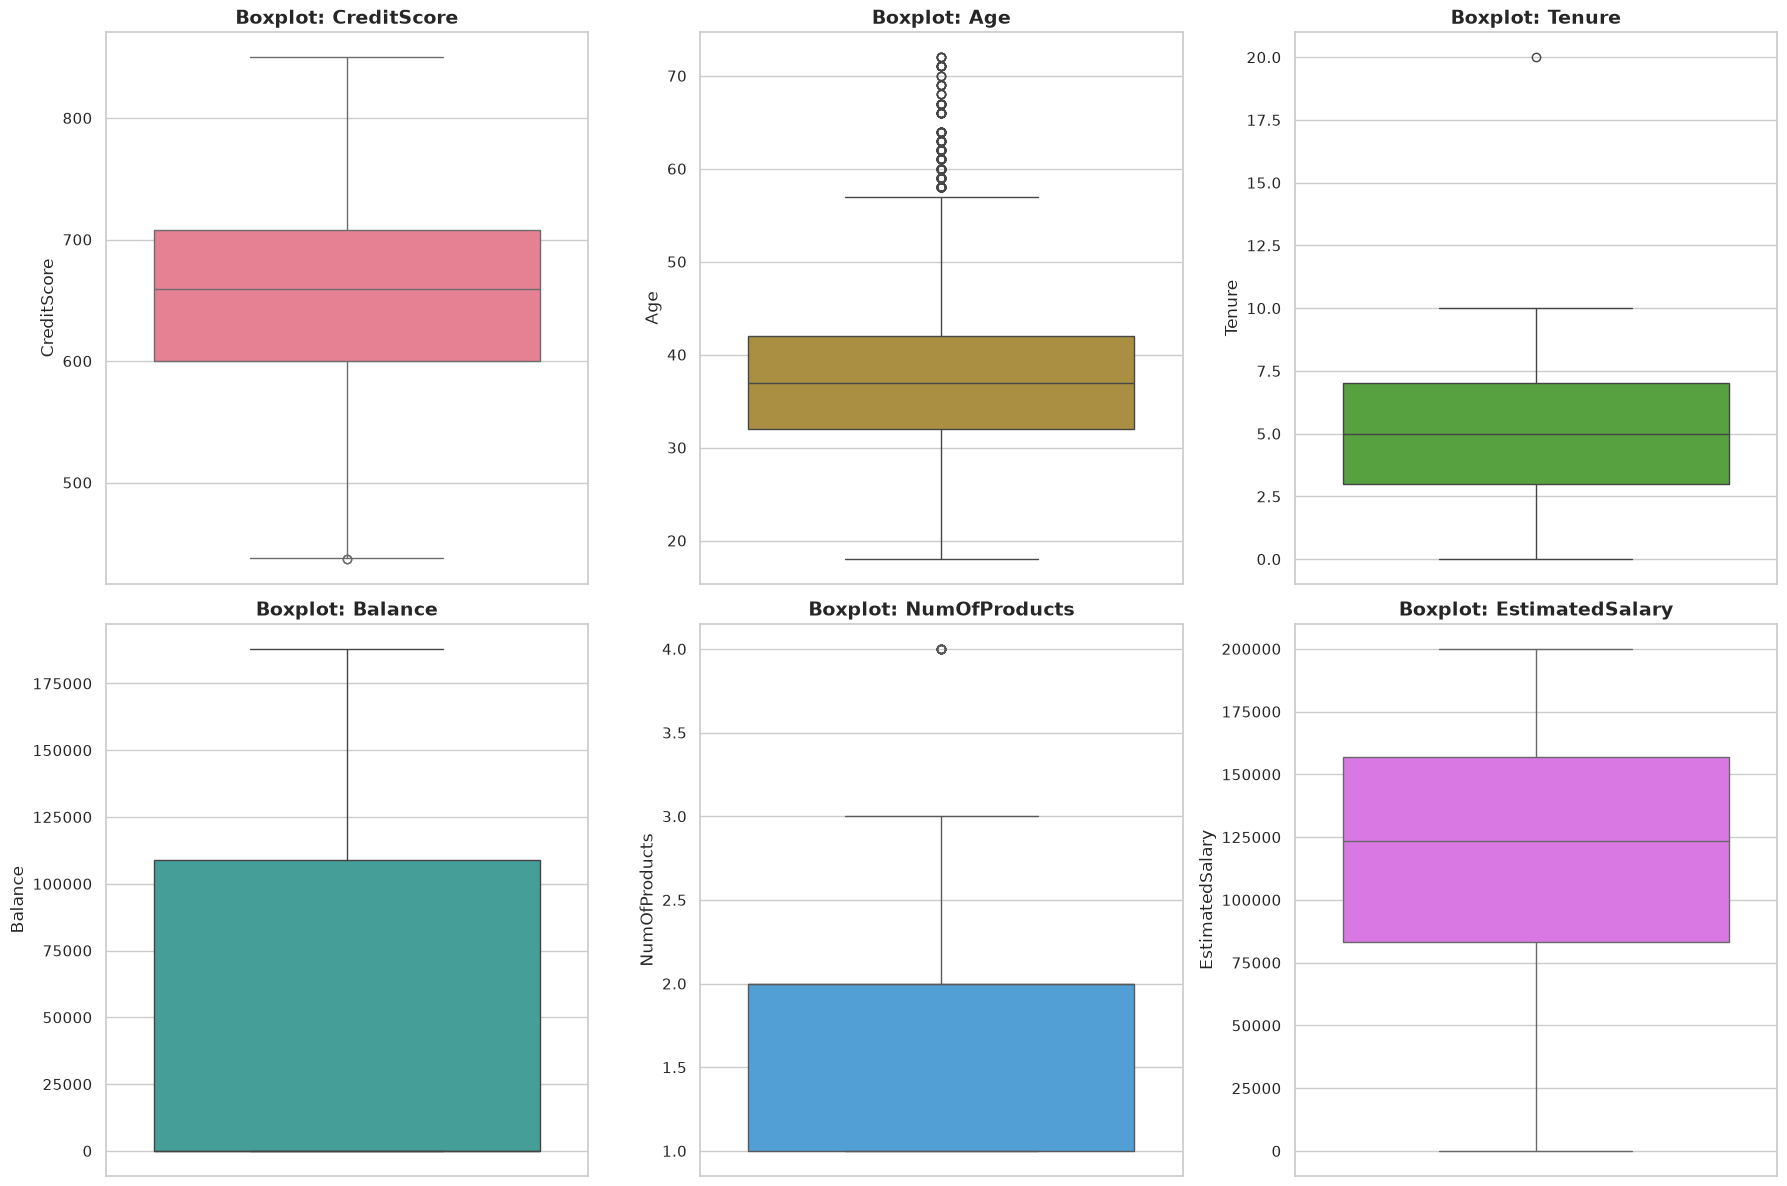

In [12]:
numerical_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 
                  'EstimatedSalary']

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    if idx < len(axes):
        # Гистограмма
        axes[idx].hist(df[col], bins=30, color=sns.color_palette('husl')[idx % 6], 
                      edgecolor='black', alpha=0.7)
        axes[idx].set_title(f'Распределение: {col}', fontsize=14, fontweight='bold')
        axes[idx].set_xlabel(col, fontsize=12)
        axes[idx].set_ylabel('Частота', fontsize=12)
        
        # Статистики
        mean_val = df[col].mean()
        median_val = df[col].median()
        axes[idx].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Среднее: {mean_val:.2f}')
        axes[idx].axvline(median_val, color='green', linestyle='--', linewidth=2, label=f'Медиана: {median_val:.2f}')
        axes[idx].legend(fontsize=9)

plt.tight_layout()
plt.show()

# Боксплоты для выявления выбросов
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    if idx < len(axes):
        sns.boxplot(data=df, y=col, ax=axes[idx], 
                   color=sns.color_palette('husl')[idx % 6])
        axes[idx].set_title(f'Boxplot: {col}', fontsize=14, fontweight='bold')
        axes[idx].set_ylabel(col, fontsize=12)

plt.tight_layout()
plt.show()

#### Биварный анализ: численные признаки x целевая переменная (Exited)

Средние значения признаков для ушедших vs оставшихся:
--------------------------------------------------------------------------------
                       Остался           Ушел       Разница  Изменение, %
CreditScore         659.717087     650.571251     -9.145836          -1.4
Age                  36.006885      45.356669      9.349784          26.0
Tenure                5.028270       5.075808      0.047537           0.9
Balance           37922.705288   59914.057175  21991.351887          58.0
NumOfProducts         1.664198       1.268020     -0.396178         -23.8
EstimatedSalary  116882.680589  121347.800108   4465.119518           3.8


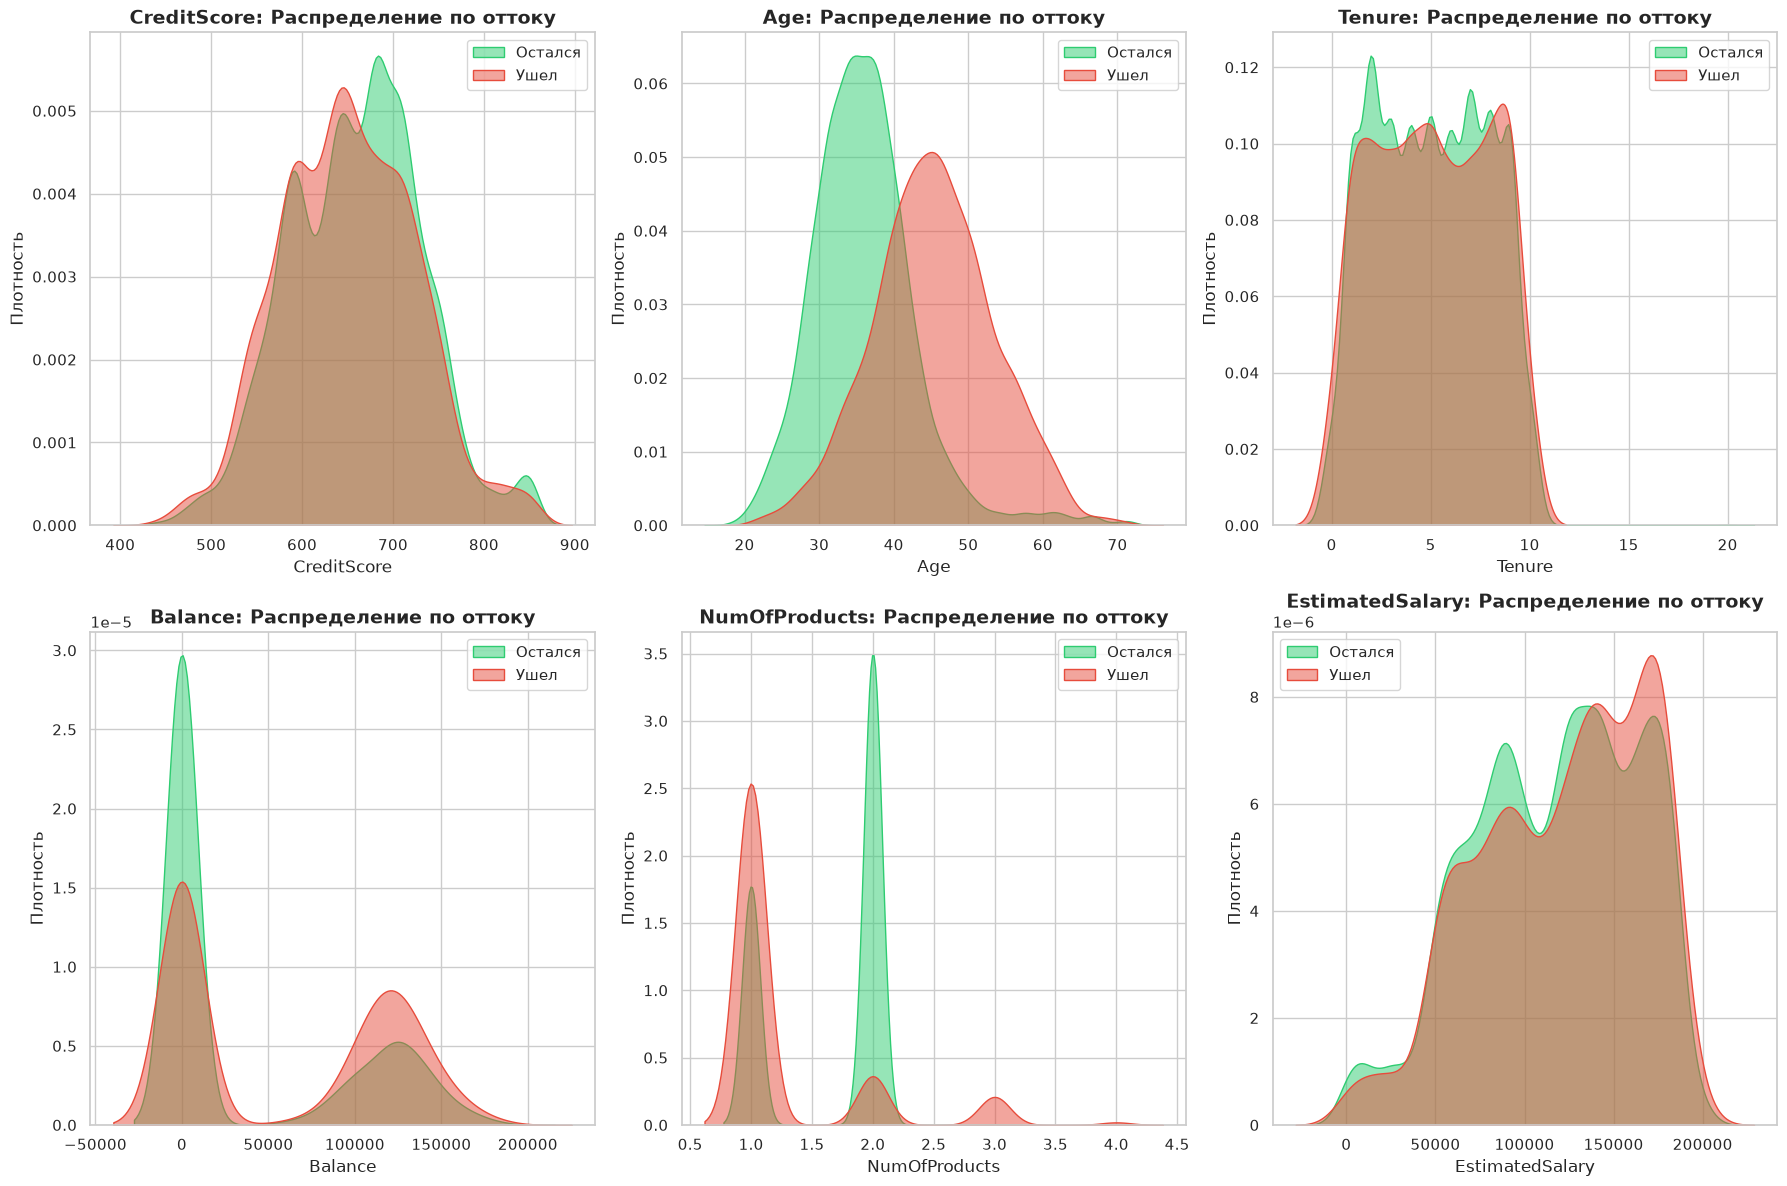

In [13]:
# Сравнение средних для ушедших и оставшихся
print('Средние значения признаков для ушедших vs оставшихся:')
print('-' * 80)
comparison = df.groupby('Exited')[numerical_cols].mean().T
comparison['Разница'] = comparison[1] - comparison[0]
comparison['Изменение, %'] = ((comparison[1] - comparison[0]) / comparison[0] * 100).round(1)
comparison.columns = ['Остался', 'Ушел', 'Разница', 'Изменение, %']
print(comparison)

# Графики распределения по классам
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    if idx < len(axes):
        # KDE plot для сравнения распределений
        sns.kdeplot(data=df[df['Exited'] == 0], x=col, ax=axes[idx], 
                   label='Остался', color='#2ecc71', alpha=0.5, fill=True)
        sns.kdeplot(data=df[df['Exited'] == 1], x=col, ax=axes[idx], 
                   label='Ушел', color='#e74c3c', alpha=0.5, fill=True)
        axes[idx].set_title(f'{col}: Распределение по оттоку', fontsize=14, fontweight='bold')
        axes[idx].set_xlabel(col, fontsize=12)
        axes[idx].set_ylabel('Плотность', fontsize=12)
        axes[idx].legend()

plt.tight_layout()
plt.show()

#### Анализ географии

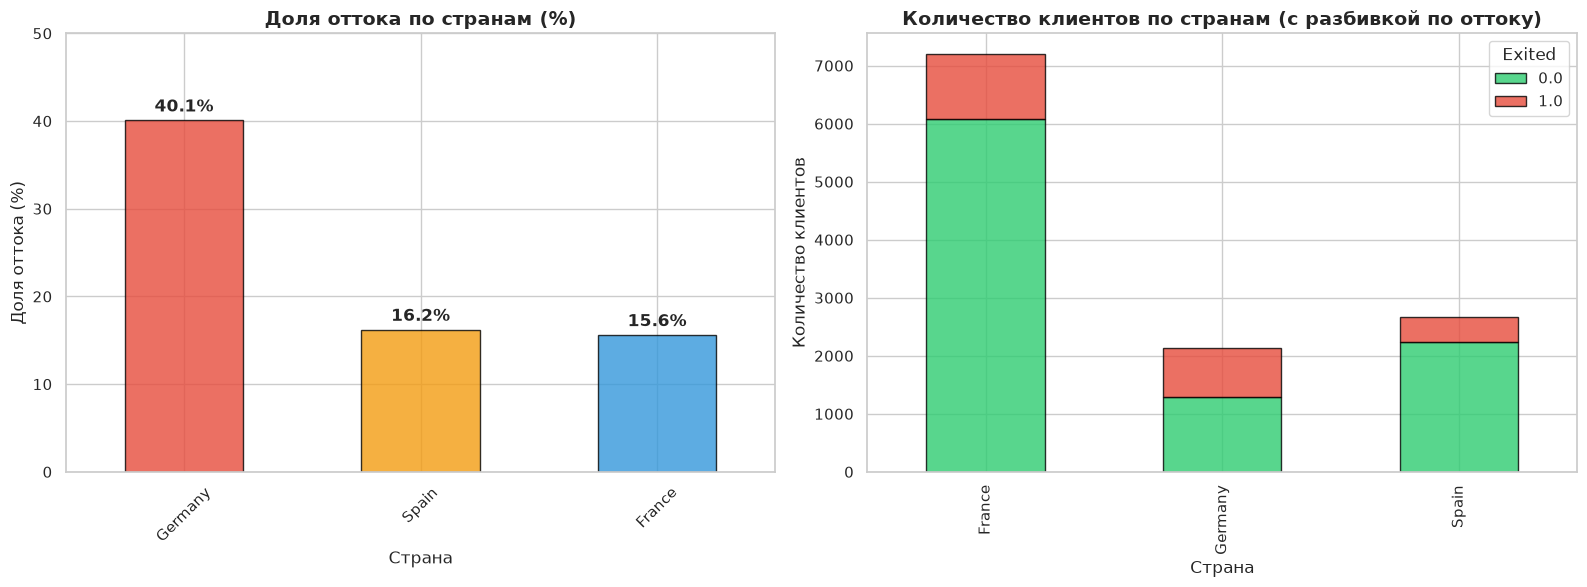

Детальная таблица по Geography:
--------------------------------------------------
           Всего клиентов    Ушло Доля оттока
Geography                                    
France               7197  1124.0       15.6%
Germany              2140   858.0       40.1%
Spain                2663   432.0       16.2%


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Доля оттока по странам
churn_by_geography = df.groupby(['Geography', 'Exited']).size().unstack(fill_value=0)
churn_rate_geography = (churn_by_geography[1] / churn_by_geography.sum(axis=1) * 100).sort_values(ascending=False)

bars = churn_rate_geography.plot(kind='bar', ax=axes[0], color=['#e74c3c', '#f39c12', '#3498db'],
                                 edgecolor='black', alpha=0.8)
axes[0].set_title('Доля оттока по странам (%)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Страна', fontsize=12)
axes[0].set_ylabel('Доля оттока (%)', fontsize=12)
axes[0].set_ylim(0, 50)

for i, v in enumerate(churn_rate_geography):
    axes[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=12)

plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45)

# Количество клиентов по странам и оттоку
churn_by_geography.plot(kind='bar', ax=axes[1], stacked=True, 
                       color=['#2ecc71', '#e74c3c'], edgecolor='black', alpha=0.8)
axes[1].set_title('Количество клиентов по странам (с разбивкой по оттоку)', 
                 fontsize=14, fontweight='bold')
axes[1].set_xlabel('Страна', fontsize=12)
axes[1].set_ylabel('Количество клиентов', fontsize=12)

plt.tight_layout()
plt.show()

# Таблица с детальным анализом
print('Детальная таблица по Geography:')
print('-' * 50)
geo_table = df.groupby('Geography')['Exited'].agg(['count', 'sum', 'mean']).round(3)
geo_table.columns = ['Всего клиентов', 'Ушло', 'Доля оттока']
geo_table['Доля оттока'] = geo_table['Доля оттока'].apply(lambda x: f'{x:.1%}')
geo_table = geo_table.sort_values('Ушло', ascending=False)
print(geo_table)

Клиенты из Германии имеют аномально высокий отток (>40%, что более чем в 2 раза превышает показатель по другим странам).  
Судя по все имеется какая-то специфика этого рынка, стоит завести дополнительный признак `is_germany`.

#### Анализ количества продуктов

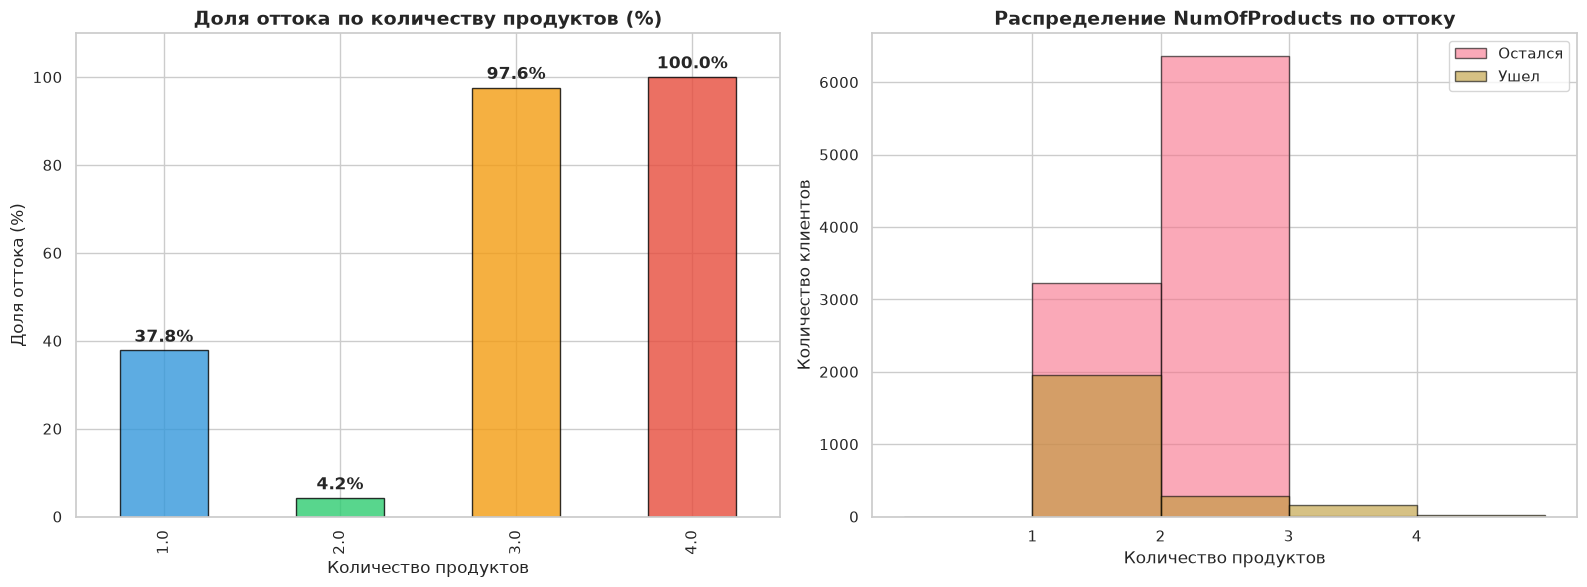

Детальная таблица по NumOfProducts:
--------------------------------------------------
               Всего клиентов    Ушло Доля оттока
NumOfProducts                                    
1.0                      5181  1958.0       37.8%
2.0                      6639   280.0        4.2%
3.0                       165   161.0       97.6%
4.0                        15    15.0      100.0%


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Доля оттока по количеству продуктов
churn_by_products = df.groupby(['NumOfProducts', 'Exited']).size().unstack(fill_value=0)
churn_rate_products = (churn_by_products[1] / churn_by_products.sum(axis=1) * 100)

bars = churn_rate_products.plot(kind='bar', ax=axes[0], color=['#3498db', '#2ecc71', '#f39c12', '#e74c3c'],
                                edgecolor='black', alpha=0.8)
axes[0].set_title('Доля оттока по количеству продуктов (%)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Количество продуктов', fontsize=12)
axes[0].set_ylabel('Доля оттока (%)', fontsize=12)
axes[0].set_ylim(0, 110)

for i, v in enumerate(churn_rate_products):
    axes[0].text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=12)

# Распределение по оттоку
for exited_val in [0, 1]:
    subset = df[df['Exited'] == exited_val]
    label = 'Остался' if exited_val == 0 else 'Ушел'
    axes[1].hist(subset['NumOfProducts'], bins=range(0, 6), alpha=0.6, 
                label=label, edgecolor='black')

axes[1].set_title('Распределение NumOfProducts по оттоку', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Количество продуктов', fontsize=12)
axes[1].set_ylabel('Количество клиентов', fontsize=12)
axes[1].legend()
axes[1].set_xticks(range(1, 5))

plt.tight_layout()
plt.show()

# Таблица
print('Детальная таблица по NumOfProducts:')
print('-' * 50)
products_table = df.groupby('NumOfProducts')['Exited'].agg(['count', 'sum', 'mean']).round(3)
products_table.columns = ['Всего клиентов', 'Ушло', 'Доля оттока']
products_table['Доля оттока'] = products_table['Доля оттока'].apply(lambda x: f'{x:.1%}')
print(products_table)


На графике количества продуктов наблюдаем V-образную яму. Клиенты с 1 продуктом имеют существенный отток, а с 3-4 - критически высокий >97%. Стоит создать два независимых бинарных признака `is_3plus_products` и `is_single_product`.

#### Анализ возраста

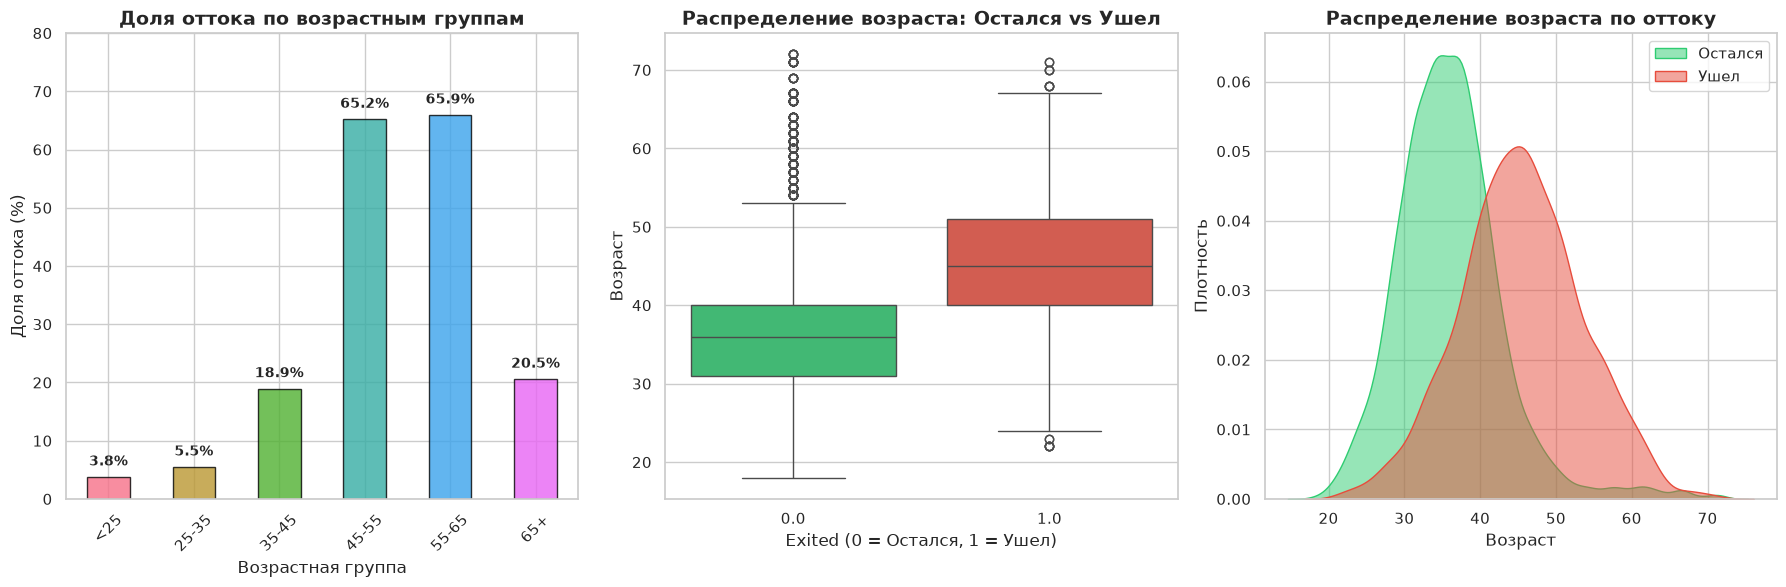

Детальная таблица по возрастным группам:
--------------------------------------------------
          Всего клиентов   Ушло Доля оттока
AgeGroup                                   
<25                  426   16.0        3.8%
25-35               4632  253.0        5.5%
35-45               5080  961.0       18.9%
45-55               1390  906.0       65.2%
55-65                399  263.0       65.9%
65+                   73   15.0       20.5%


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Средний отток по возрастным группам
age_bins = pd.cut(df['Age'], bins=[0, 25, 35, 45, 55, 65, 100], 
                  labels=['<25', '25-35', '35-45', '45-55', '55-65', '65+'])
df['AgeGroup'] = age_bins
churn_by_age = df.groupby('AgeGroup')['Exited'].mean() * 100

churn_by_age.plot(kind='bar', ax=axes[0], color=sns.color_palette("husl", len(churn_by_age)),
                 edgecolor='black', alpha=0.8)
axes[0].set_title('Доля оттока по возрастным группам', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Возрастная группа', fontsize=12)
axes[0].set_ylabel('Доля оттока (%)', fontsize=12)
axes[0].set_ylim(0, 80)

for i, v in enumerate(churn_by_age):
    axes[0].text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=10)

plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45)

# Boxplot возраста по оттоку
sns.boxplot(data=df, x='Exited', y='Age', ax=axes[1], palette=['#2ecc71', '#e74c3c'])
axes[1].set_title('Распределение возраста: Остался vs Ушел', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Exited (0 = Остался, 1 = Ушел)', fontsize=12)
axes[1].set_ylabel('Возраст', fontsize=12)

# KDE plot
sns.kdeplot(data=df[df['Exited'] == 0], x='Age', ax=axes[2], 
           label='Остался', color='#2ecc71', alpha=0.5, fill=True)
sns.kdeplot(data=df[df['Exited'] == 1], x='Age', ax=axes[2], 
           label='Ушел', color='#e74c3c', alpha=0.5, fill=True)
axes[2].set_title('Распределение возраста по оттоку', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Возраст', fontsize=12)
axes[2].set_ylabel('Плотность', fontsize=12)
axes[2].legend()

plt.tight_layout()
plt.show()

# Таблица
print("Детальная таблица по возрастным группам:")
print("-" * 50)
age_table = df.groupby('AgeGroup')['Exited'].agg(['count', 'sum', 'mean']).round(3)
age_table.columns = ['Всего клиентов', 'Ушло', 'Доля оттока']
age_table['Доля оттока'] = age_table['Доля оттока'].apply(lambda x: f'{x:.1%}')
print(age_table)

Основная категория оттока в этом датасете — это возраст старше 45 лет. Группа 45-65 лет составляет всего ~15% от базы (1789 человек), но генерирует почти 50% всего оттока в датасете (1169 из 2414 ушедших). Стоит создать бинарный признак `is_age_over_45`.

#### Анализ баланса

На гистограмме (график выше) распределения баланса явно выделяются две группы клиентов, с небольшим балансом и балансом около 100_000 и более, рассмотрим их поподробнее:

In [19]:
print("Статистика оттока по ключевым группам баланса:")
print("-" * 60)

# Создаем временные группы для анализа
analysis_df = df.copy()
analysis_df['balance_group'] = pd.cut(analysis_df['Balance'], 
                                      bins=[-1, 10, 100000, np.inf], 
                                      labels=['~0 (до 10)', 'Средний (10-100к)', 'Высокий (>100к)'])

stats = analysis_df.groupby('balance_group')['Exited'].agg(['count', 'sum', 'mean']).round(3)
stats.columns = ['Всего клиентов', 'Ушло', 'Доля оттока']
stats['Доля оттока'] = stats['Доля оттока'].apply(lambda x: f'{x:.1%}')
print(stats)

# Проверка комбинации высокий баланс + Неактивен
print("\nПроверка комбинации (Высокий баланс х Активность):")
high_balance_inactive = analysis_df[(analysis_df['Balance'] > 100000) & (analysis_df['IsActiveMember'] == 0)]
hb_active = analysis_df[(analysis_df['Balance'] > 100000) & (analysis_df['IsActiveMember'] == 1)]

print(f" - Высокий баланс + НЕАКТИВЕН: {len(high_balance_inactive)} чел., отток: {high_balance_inactive['Exited'].mean():.1%}")
print(f" - Высокий баланс + АКТИВЕН:   {len(hb_active)} чел., отток: {hb_active['Exited'].mean():.1%}")


Статистика оттока по ключевым группам баланса:
------------------------------------------------------------
                   Всего клиентов    Ушло Доля оттока
balance_group                                        
~0 (до 10)                   7830  1231.0       15.7%
Средний (10-100к)             675   136.0       20.1%
Высокий (>100к)              3495  1047.0       30.0%

Проверка комбинации (Высокий баланс х Активность):
 - Высокий баланс + НЕАКТИВЕН: 1804 чел., отток: 40.2%
 - Высокий баланс + АКТИВЕН:   1691 чел., отток: 19.0%


Аномально высокий отток у неактивных клиентов с высоким балансом, а у клиентов с нулевым балансом (0-10) самый низкий отток, поэтому есть большой смысл в создании новых признаков `is_high_balance_inactive` и `is_zero_balance`.

#### Корреляционная матрица

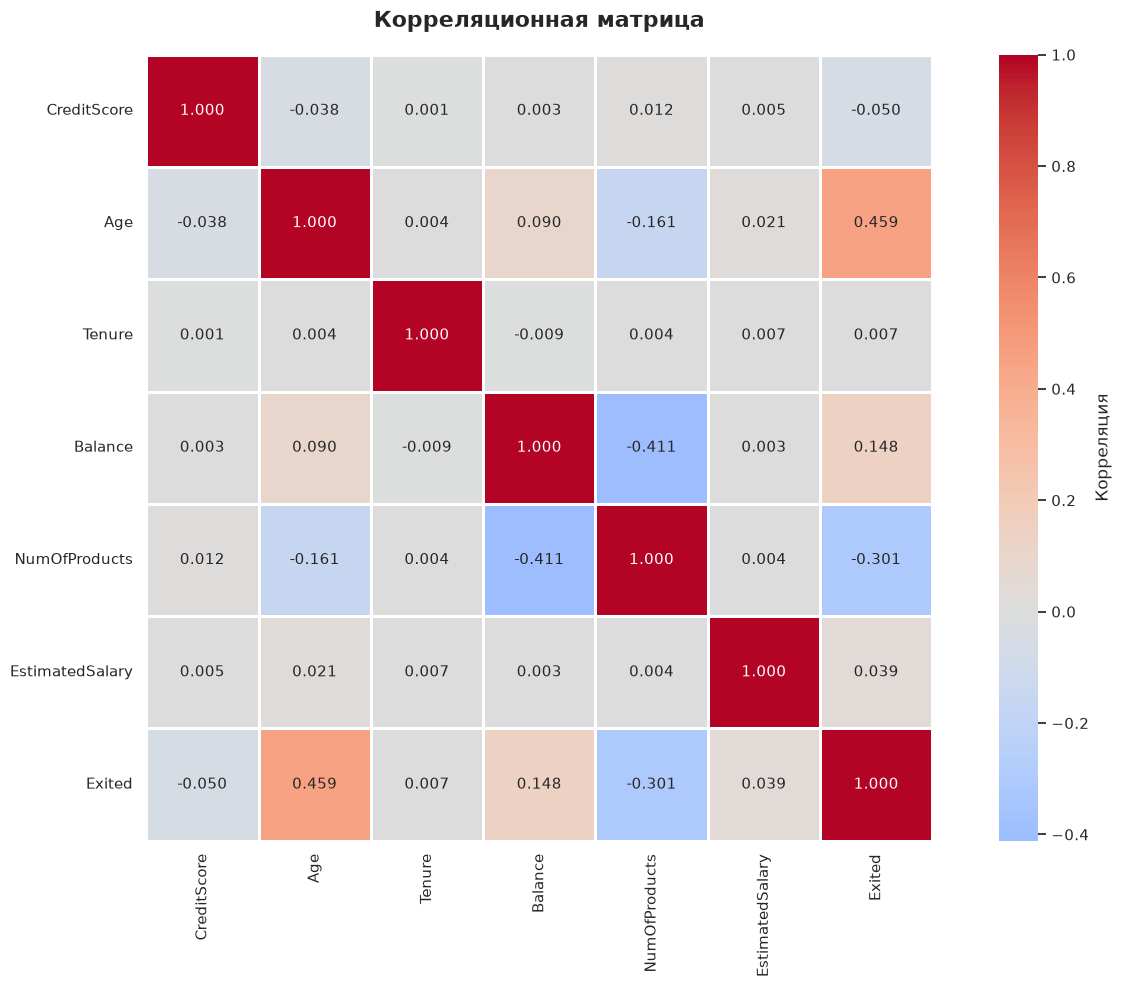

Топ-корреляции с Exited (отток):
------------------------------
Age                0.459395
NumOfProducts      0.301289
Balance            0.148162
CreditScore        0.050305
EstimatedSalary    0.039044
Tenure             0.006802
Name: Exited, dtype: float64


In [20]:
corr_matrix = df[numerical_cols + ['Exited']].corr()

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0,
           square=True, linewidths=1, cbar_kws={'label': 'Корреляция'})
ax.set_title('Корреляционная матрица', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Топ корреляций с целевой переменной
print("Топ-корреляции с Exited (отток):")
print("-" * 30)
correlation_with_target = corr_matrix['Exited'].drop('Exited').abs().sort_values(ascending=False)
print(correlation_with_target)

Уникальных фамилий: 752
Топ-10 фамилий:
Surname
Ch'iu      207
Hsia       182
Ch'ang     174
T'ien      164
Ch'ien     159
Ch'eng     140
Hs?        138
Chiu       125
Maclean    123
Hsueh      121
Name: count, dtype: int64


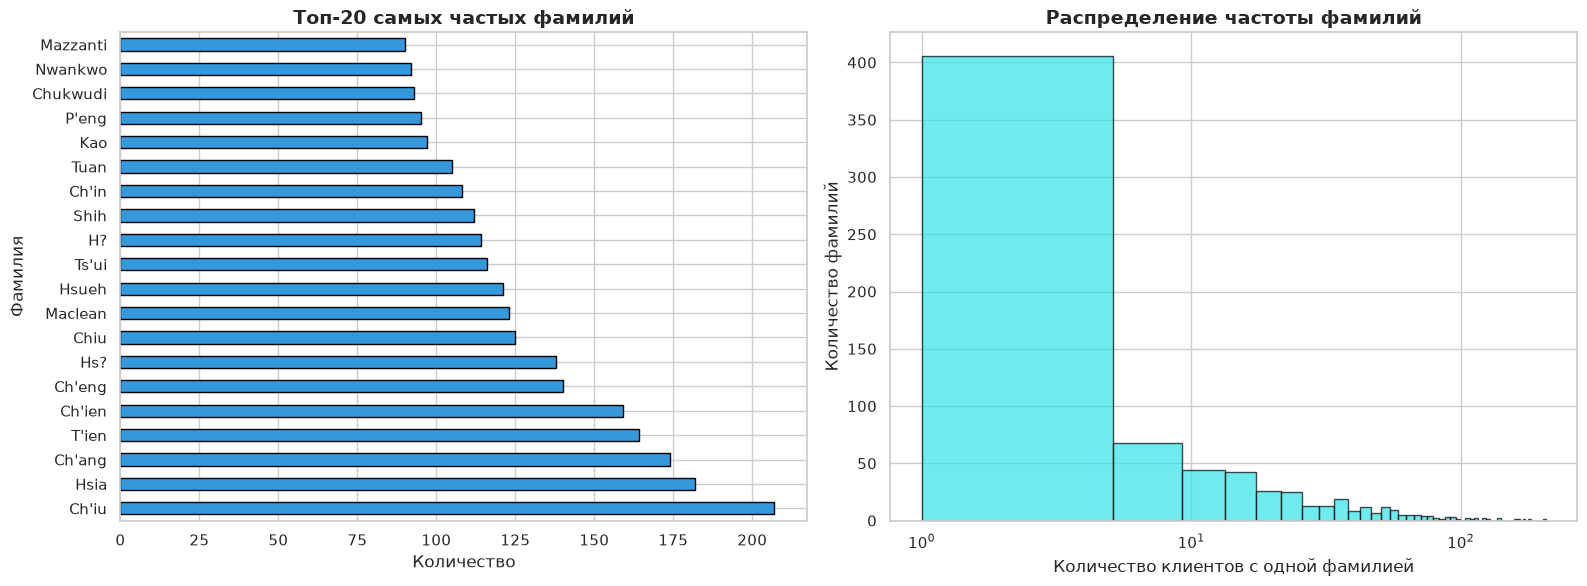

Отток по частоте фамилий:
surname_freq
Очень редкие    21.312838
Редкие          21.744325
Средние         18.265039
Частые          19.792961
Очень частые    19.300464
Name: Exited, dtype: float64


In [21]:
if 'Surname' in df.columns:
    surname_stats = df['Surname'].value_counts()
    print(f"Уникальных фамилий: {len(surname_stats)}")
    print(f"Топ-10 фамилий:")
    print(surname_stats.head(10))
    
    # Частотный анализ
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Топ-20 фамилий
    surname_stats.head(20).plot(kind='barh', ax=axes[0], color='#3498db', edgecolor='black')
    axes[0].set_title('Топ-20 самых частых фамилий', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Количество', fontsize=12)
    axes[0].set_ylabel('Фамилия', fontsize=12)
    
    # Распределение частоты
    axes[1].hist(surname_stats, bins=50, color="#31e3e9", edgecolor='black', alpha=0.7)
    axes[1].set_title('Распределение частоты фамилий', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Количество клиентов с одной фамилией', fontsize=12)
    axes[1].set_ylabel('Количество фамилий', fontsize=12)
    axes[1].set_xscale('log')
    
    plt.tight_layout()
    plt.show()
    
    # Отток по частоте фамилий
    df['surname_freq'] = df['Surname'].map(surname_stats)
    
    print("Отток по частоте фамилий:")
    freq_bins = pd.qcut(df['surname_freq'], q=5, labels=['Очень редкие', 'Редкие', 'Средние', 'Частые', 'Очень частые'])
    churn_by_freq = df.groupby(freq_bins)['Exited'].mean() * 100
    print(churn_by_freq)

Признак `Surname` не представляет для нас какой-либо ценности, а вполне может даже и навредить, так что его стоит удалить.

## Summary: 

По результатам EDA выявлены закономерности в данных, которые будут положены в основу инжиниринга новых фичей:  
- `is_germany` (Geography)
- `is_single_product` и `is_3plus_products` (NumOfProducts)
- `is_age_over_45` (Age)
- `is_zero_balance` (Balance <= 10)
- `is_high_balance_inactive` (Balance > 100_000 и IsActiveMember = 0)

Столбцы `id`, `CustomerId`, `Surname` будут удалены за ненадобностью.

Для удобства, очистка и подготовка признаков, а также обучение модели, будут вынесены в отдельные файлы.